#Ejercicio 1

## 1. Preparación del Entorno 
Para la preparación del entorno descargamos el fichero .csv que contiene la información de nuestro dataset. Además hacemos un análisis exploratorio de los datos para la posterior construcción de nuestro modelo. 


### 1.1. Descarga inicial de Datos y Exploración
Cargamos nuestro conjunto de datos y aplicamos las funciones `df.info()`, `df.describe()` para entender la estructura interna de nuestro data frame. 

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Configuramos el estilo visual general
sns.set_theme(style="whitegrid")

#Cargamos el conjunto de datos
url_data = 'fifa_22_official_players_data.csv'

print(f"Dimensiones del dataset: {df.shape[0]} registros y {df.shape[1]} columnas.")

#Resumen general de las variables y de sus tipos de datos
print("\n---Características---")
print(df.info())
df[['overall', 'potential', 'value_eur', 'pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic']].describe()


Dimensiones del dataset: 19239 registros y 73 columnas.

---Características---
<class 'pandas.DataFrame'>
RangeIndex: 19239 entries, 0 to 19238
Data columns (total 73 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   sofifa_id                    19239 non-null  int64  
 1   short_name                   19239 non-null  str    
 2   long_name                    19239 non-null  str    
 3   overall                      19239 non-null  int64  
 4   potential                    19239 non-null  int64  
 5   value_eur                    19165 non-null  float64
 6   wage_eur                     19178 non-null  float64
 7   age                          19239 non-null  int64  
 8   dob                          19239 non-null  str    
 9   height_cm                    19239 non-null  int64  
 10  weight_kg                    19239 non-null  int64  
 11  club_team_id                 19178 non-null  float64
 12  club_n

,overall,potential,value_eur,pace,shooting,passing,dribbling,defending,physic
count,19239.000000,19239.000000,1.916500e+04,17107.000000,17107.000000,17107.000000,17107.000000,17107.000000,17107.000000
mean,65.772182,71.079370,2.850452e+06,68.213071,52.345297,57.312562,62.561174,51.703630,64.823289
std,6.880232,6.086213,7.613700e+06,10.933155,14.051623,10.068965,9.651312,16.189746,9.791886
min,47.000000,49.000000,9.000000e+03,28.000000,18.000000,25.000000,27.000000,14.000000,29.000000
25%,61.000000,67.000000,4.750000e+05,62.000000,42.000000,51.000000,57.000000,37.000000,59.000000
50%,66.000000,71.000000,9.750000e+05,69.000000,54.000000,58.000000,64.000000,56.000000,66.000000
75%,70.000000,75.000000,2.000000e+06,76.000000,63.000000,64.000000,69.000000,64.000000,72.000000
max,93.000000,95.000000,1.940000e+08,97.000000,94.000000,93.000000,95.000000,91.000000,90.000000


El conjunto de datos de FIFA 22 contiene 19.239 registros y 73 columnasn donde cada registro representa a un futbolista.

Se identifican los siguientes tipos de variables:

* **Cualitativas nominales:** nombres,nacionalidad,club,liga,posición y pierna preferida.
* **Cuantitativas:** edad,altura,peso,valor económico,salario y cláusula de rescisión.
* **Ordinales:** valoración general,potencial,reputación internacional y puntuaciones de habilidades.
* **Temporales:** fecha de nacimiento, incorporación al club y finalización del contrato.
* **Identificadores:** `sofia_id`, `club_tema_id`, `nacionality_id`.

El análisis muestra que la media es de 65,77 mientras que el potencial medio es de 71,88, indicando que mucbos jugadores pueden mejorar su nivel. En cuanto al valor económico medio es de 2,85 millones de euros, aunque la mediana inferior es de 975.000 euros, debido a la existencia de algunos jugadores con valores muy elevados.

También se observan valores ausentes, especialmente en las estadísticas deportivas generales y en los datos relacionados con selecciones nacionales, cesiones. 

#### 1.1.1. Exploración de las Distribuciones

En esta fase se analiza cómo se distribuyen los valores de las principales variables numéricas de nuestro dataset con la ayuda de un histograma. Cada histograma divide los valores en 30 intervalos y muestra cuántos jugadores se encuentran en cada rango. Además la curva KDE suaviza la distribución para facilitar la identificación de tendencias como contraciones de valores, posibles asímetrias. Los valores ausentes para que no generen ruido se eliminan con dropna().


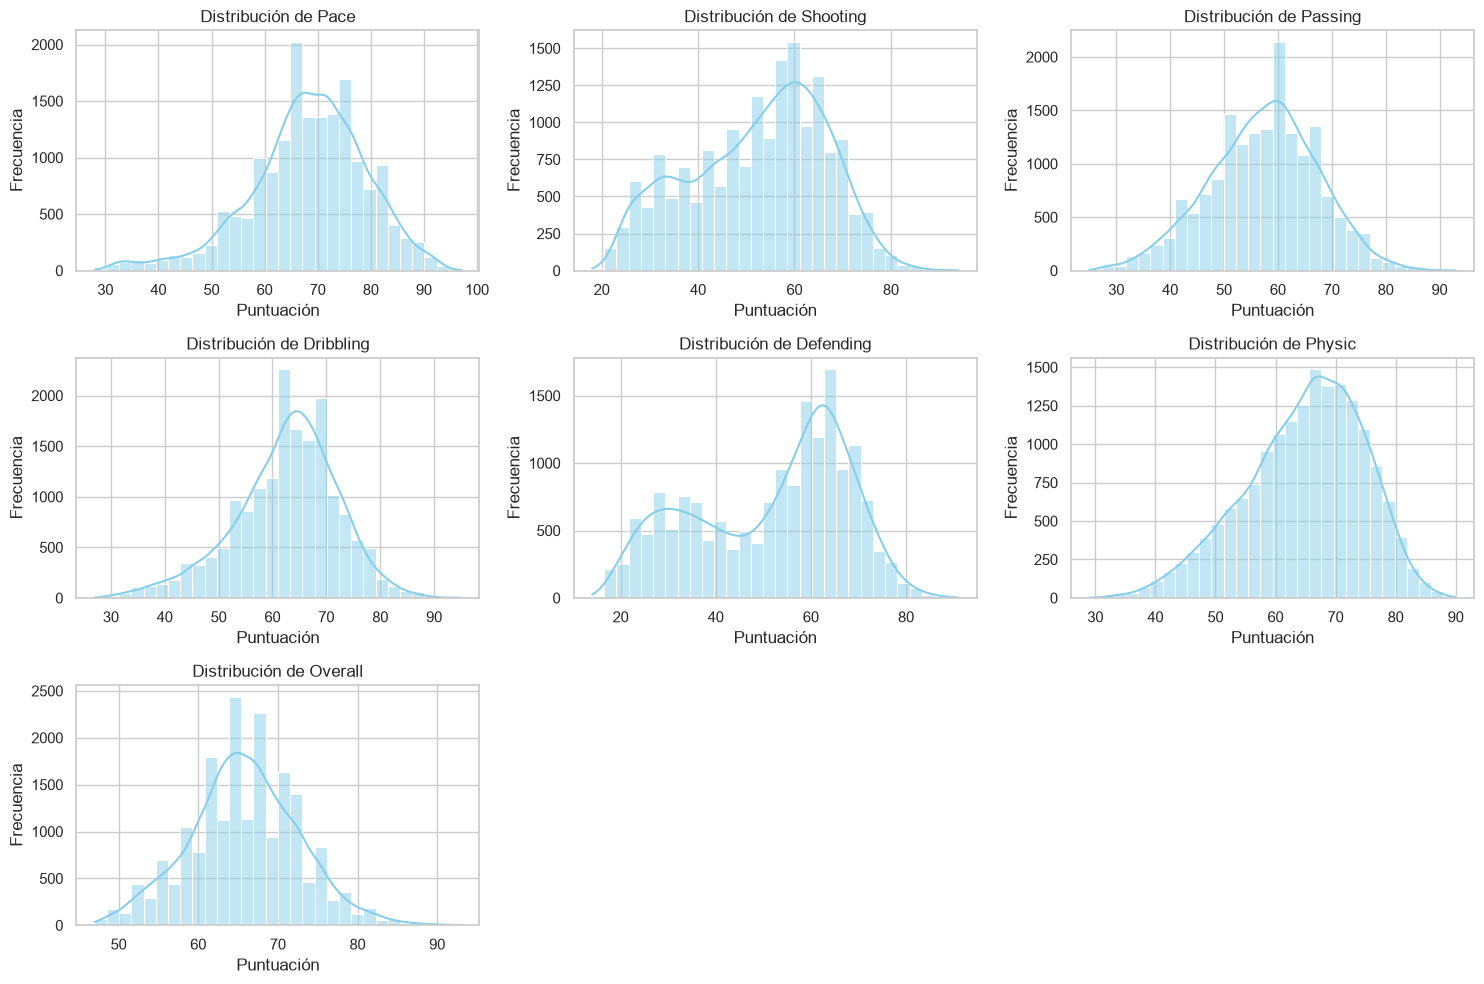

In [3]:
# lista de las características físicas y técnicas principales
features_num = ['pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic', 'overall']
#Histograma para analizar la forma de las distribuciones
plt.figure(figsize=(15, 10))
for i, col in enumerate(features_num, 1):
    plt.subplot(3, 3, i)
    sns.histplot(df[col].dropna(), kde=True, bins=30, color='skyblue')
    plt.title(f'Distribución de {col.capitalize()}')
    plt.xlabel('Puntuación')
    plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

Los resultados demuestran que la mayoría de los jugadores tienen puntuaciones medias, mientras que los valores muy bajos o muy altos son menos frecuentes. También se aprecia que todas las variabels tienen la misma variabilidad: `defending` es más disperas, mientras que `overall` está más concentrada. Esta gráfica nos ayuda a identificar los valores extremos que en nuestro caso, no hay datos tan evidentes pero si tenemos valores altos como los de overall. 

#### 1.1.2. Análisis de  Variables 
Analizamos las variables principales mediante correlaciones, este análisis permite identificar qué factores están más relacionados con el nivel de un futbolista y comprobar si existen diferencias según su pierna preferida, posición, liga, valor de mercado o pertenencia al grupo de jugadores de élite.

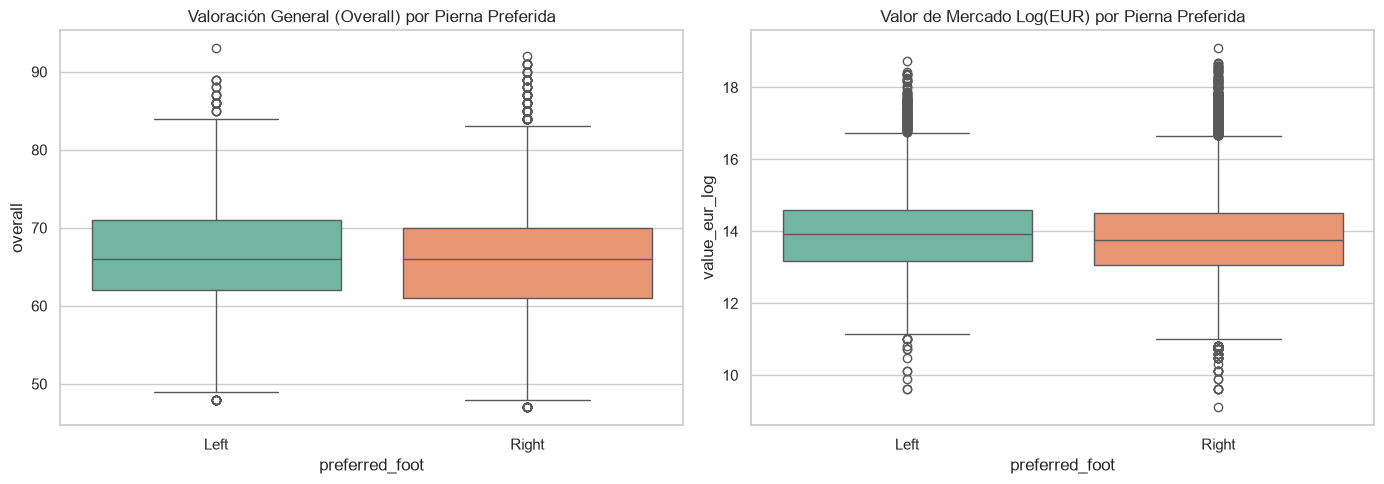

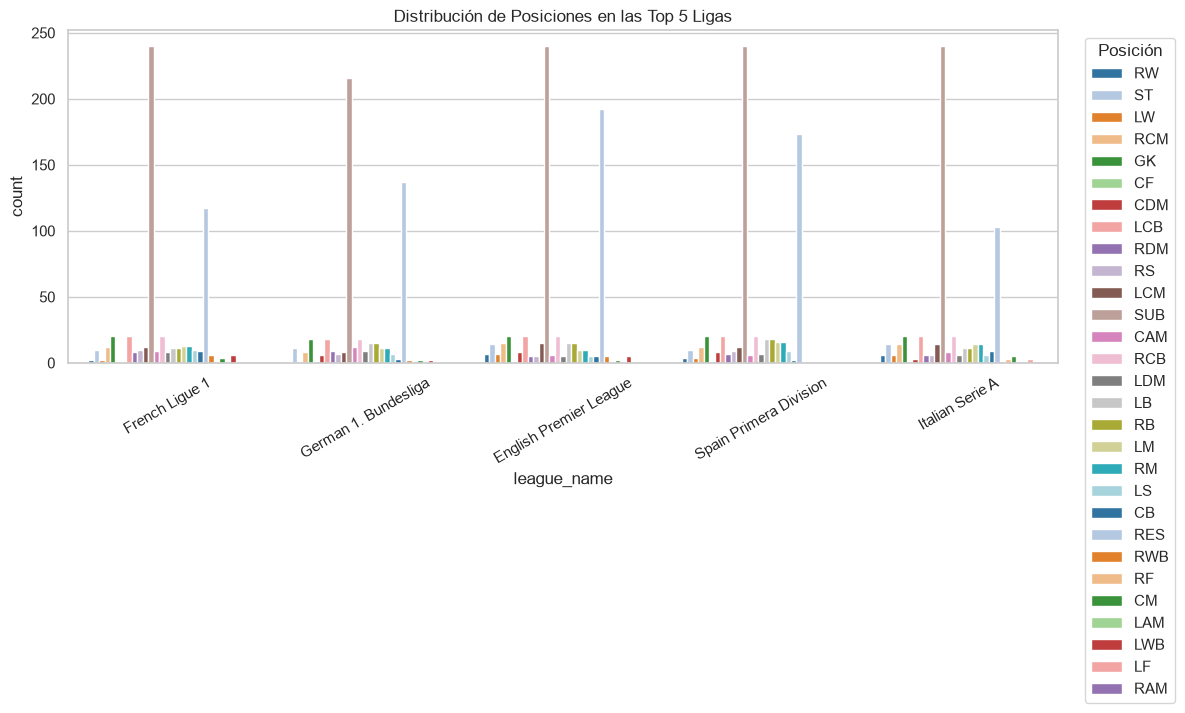

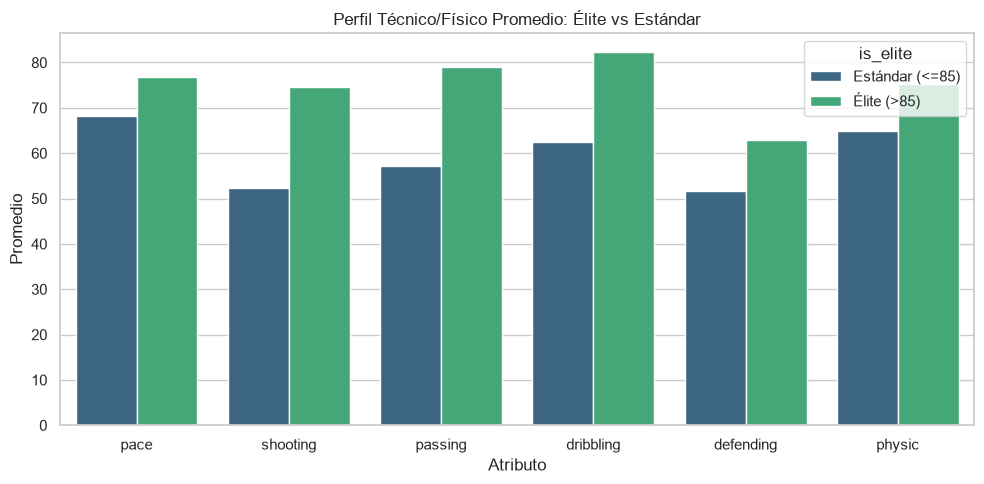

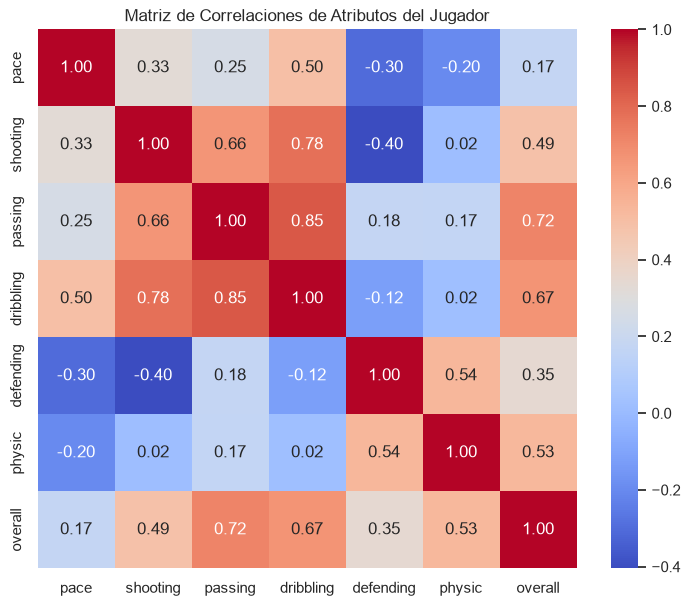

In [15]:
# 3. RELACIÓN Y ASOCIACIÓN ENTRE VARIABLES

# A) Pierna preferida vs Valoración general y Valor económico
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Overall vs Preferred Foot
sns.boxplot(data=df, x='preferred_foot', y='overall', hue='preferred_foot', ax=axes[0], palette='Set2', legend=False)
axes[0].set_title('Valoración General (Overall) por Pierna Preferida')

# Logaritmo del Valor de mercado vs Preferred Foot
df['value_eur_log'] = np.log1p(df['value_eur'])
sns.boxplot(data=df, x='preferred_foot', y='value_eur_log', hue='preferred_foot', ax=axes[1], palette='Set2', legend=False)
axes[1].set_title('Valor de Mercado Log(EUR) por Pierna Preferida')

plt.tight_layout()
plt.show()

# B) Relación entre Ligas Top 5 y Posición del Jugador
df['main_position'] = df['position'].str.split(',').str[0].str.strip()
top_leagues = ['Spain Primera Division', 'English Premier League', 'Italian Serie A', 'French Ligue 1', 'German 1. Bundesliga']
df_top = df[df['league_name'].isin(top_leagues)]

plt.figure(figsize=(12, 6))
sns.countplot(data=df_top, x='league_name', hue='main_position', palette='tab20')
plt.title('Distribución de Posiciones en las Top 5 Ligas')
plt.xticks(rotation=30)
plt.legend(title='Posición', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# C) Comparativa de atributos en Jugadores de Élite (Overall > 85)
df['is_elite'] = np.where(df['overall'] > 85, 'Élite (>85)', 'Estándar (<=85)')
df_elite = df.groupby('is_elite')[['pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic']].mean().reset_index()
df_elite_melted = df_elite.melt(id_vars='is_elite', var_name='Atributo', value_name='Promedio')

plt.figure(figsize=(10, 5))
sns.barplot(data=df_elite_melted, x='Atributo', y='Promedio', hue='is_elite', palette='viridis')
plt.title('Perfil Técnico/Físico Promedio: Élite vs Estándar')
plt.tight_layout()
plt.show()

# D) Matriz de correlaciones entre variables técnicas y físicas
plt.figure(figsize=(9, 7))
sns.heatmap(df[['pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic', 'overall']].corr(), 
            annot=True, cmap='coolwarm', fmt='.2f', square=True)
plt.title('Matriz de Correlaciones de Atributos del Jugador')
plt.show()

La relación entre las variables podemos destacar: 

* **Pierna preferida, valoración de mercado**: Los diagramas de caja muestran que las distribuciones `overall` para jugadores diestros y zurdos son bastante similares, por lo que no afecta. Sucede lo mismo con el valor de mercado, por lo tanto, ser zurdo o diestro no interfiere el valor de mercado.

* **Liga Top 5 y posición**: El gráfico muestra cómo se distribuyen las posiciones de las cinco grandes ligas. Se observa que las posiciones más frecuentes son las de centrocampista, defensa y delantero aunque la cantidad varía.

* **Jugadores de Élite vs Jugadores Estándar**: Los jugadores de élite son aquellos que presentan un overall > 85 prsentan medias superiores en casi todos los atributos. La diferencia se aprecia en atributos técnicos como `shooting`,`passing` y `dribbling`. Esto indica que los jugadores mejor valorados nsuelen destacar de forma global. 

* **Matriz de Correlaciones**:La relación más importante es la de overall con atributos como `passing`, `dribbling`, `shooting` y `physic`. Esto significa que estas características están asociadas con una mayor valoración general. También existe relación entre varios atributos técnicos, como el pase y el regate.

### 1.2 Preprocesamiento de Datos y Exploración 
En este apartado preparamos el dataset para que pueda ser analizado correctamente. Se revisan los tipos de datos se localizan valores nulos, se transforman algunos datos... Además se estudia el contenido y comportamiento del dataser. Analizando su tamaño, las variables disponinles...



#### 1.2.1. Selección y Extracción de características
Hemos tomado la variable `overall` como variable objetivo porque representa la valoración general del futbolista. Además de ser una variable adecuada porque: está disponible entodos los jugadores, resume el nivel global del futbolista, tiene una escala numérica y estña relacionada con muchas variables del dataset. Además hemos extraido las siguientes carácterísticas y las hemos creado en tres variables nuevas para resumir mejor la información existente y facilitar el análisis o la predicción. 
* **media_tecnica**: combina disparo, pase y regate en una única medida del rendimiento técnico.
* **media_física**: combina ritmo, defensa y físico 
* **diferencia_potencial**: muestra cuanto puede mejorar un jugador respecto a su valoración actual.

También se han dejado fuera las variables que no son necesarias para analizar o predecir el `overall`como los identificadores, nombres descriptivos, etc. 




In [16]:
# Variable objetivo
target = 'overall'

# Características numéricas candidatas
features = ['potential', 'value_eur', 'age','pace', 'shooting', 'passing','dribbling', 'defending', 'physic']

# Extracción de nuevas características
df['media_tecnica'] = df[['shooting', 'passing', 'dribbling']].mean(axis=1)
df['media_fisica'] = df[['pace', 'defending', 'physic']].mean(axis=1)
df['diferencia_potencial'] = df['potential'] - df['overall']

# Añadimos las nuevas características
features.extend(['media_tecnica','media_fisica','diferencia_potencial'])

# Seleccionamos las variables y convertimos los datos a formato numérico
X = df[features].apply(pd.to_numeric, errors='coerce')
y = df[target]

# Eliminamos filas con valores ausentes
datos_modelo = pd.concat([X, y], axis=1).dropna()

X = datos_modelo[features]
y = datos_modelo[target]

# Selección mediante correlación con la variable objetivo
correlaciones = X.corrwith(y).abs().sort_values(ascending=False)

print("Características seleccionadas:")
display(correlaciones.round(2))

print("Dimensiones finales:")
print(f"X: {X.shape}")
print(f"y: {y.shape}")

Características seleccionadas:


passing                 0.72
dribbling               0.67
media_tecnica           0.66
potential               0.63
media_fisica            0.57
value_eur               0.56
diferencia_potencial    0.53
physic                  0.53
shooting                0.49
age                     0.46
defending               0.35
pace                    0.18
dtype: float64

Dimensiones finales:
X: (17041, 12)
y: (17041,)


Tras la extracción de características hemos conseguido reducir la dimensionalidad de nuestro conjunto de datos a 17041, 12

#### 1.2.2. Códificación de Variables Categóricas

En esta fase se transforman las variables que contienen texto en valores números. Para ello se utilizamos One-Hot-Encoding que crea una columna binaria para cada categoría. Hemos utilizado este tipo de transformación porque One-Hot-Encoding no introduce un orden artificial, facil de interpretar, es adecuado a modelos de regresión y clasificación. Las variables que vamos a codificar son:

* `main_position`: representa la posición del jugador. Se codifica prq las posiciones no tienen un orden numérico y cada uno puede estar asociada a diferentes atributos y valoraciones.
* `liga_top5`: Indica si el jugador pertenece a las cinco grandes liga 1 si pertenece 0 para el resto. 

In [17]:
# Crear la posición principal
df['main_position'] = (df['position'].astype('string').str.split(',').str[0].str.strip())

# Clasificar las ligas Top 5
top_leagues = ['España: Primera Division','Inglaterra: Premier League','Italia: Serie A','Francia: Ligue 1','Alemania: 1. Bundesliga'
]

df['liga_top5'] = df['league_name'].isin(top_leagues).astype(int)

# Codificar únicamente la posición principal
df_position = pd.get_dummies(df[['main_position']].fillna('Desconocido'),columns=['main_position'],prefix='position',dtype=int)

# Variables numéricas seleccionadas
variables_numericas = ['potential', 'value_eur', 'age','pace', 'shooting', 'passing','dribbling', 'defending', 'physic','media_tecnica', 'media_fisica','diferencia_potencial', 'liga_top5']

df_numericas = df[variables_numericas].apply(pd.to_numeric,errors='coerce')

# Unir variables numéricas y posición codificada
datos_modelo = pd.concat([df_numericas,df_position,df['overall']],axis=1)

# Eliminar filas con valores ausentes
datos_modelo = datos_modelo.dropna()

# Separar las características y la variable objetivo
X = datos_modelo.drop(columns='overall')
y = datos_modelo['overall']

print("Variables codificadas:")
display(df_position.head())

print(f"Dimensiones finales de X: {X.shape}")
print(f"Dimensiones finales de y: {y.shape}")

Variables codificadas:


,position_CAM,position_CB,position_CDM,position_CF,position_CM,position_Desconocido,position_GK,position_LAM,position_LB,position_LCB,...,position_RCM,position_RDM,position_RES,position_RF,position_RM,position_RS,position_RW,position_RWB,position_ST,position_SUB
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0


Dimensiones finales de X: (17041, 43)
Dimensiones finales de y: (17041,)


#### 1.2.3. Escalado y Normalización 


Para el escalado utilizamos `StandardScaler` porque las variables númericas tienen escalas muy diferentes como los atributos deportivos que suelen estar entre 0 y 100. 
Este escalado transforma cada variable mediante $z = \frac{x-\mu}{\sigma}$. 
* $x$: es el valor original. 
* $\mu$: es la media de todos los jugadores.  
* $\sigma$: es la desviación estandar.
De esta forma cada variable queda con media 0 y desviación estandar 1.

Hemos elegido `StandardScaler` porque: se mantiene la forma original de las distribuciones, permite comparar variables en una escala común, no convierte los valores en categorías ni elimina información. 

Además hay que tener en cuenta que no se normalizan las variables categóricas codificacas ni liga_top5 porque utilizan valores binarios 0 y 1. El escalado se ajusta únicamente con los datos de entrenamiento y después se aplica tanto al entrenamiento como a la prueba. 

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Variables numéricas que necesitan escalado
variables_numericas = ['potential', 'value_eur', 'age','pace', 'shooting', 'passing','dribbling', 'defending', 'physic','media_tecnica', 'media_fisica','diferencia_potencial']

# Nos quedamos solo con las columnas que existen en X
variables_numericas = [col for col in variables_numericas if col in X.columns]

# Separar los datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42
)

# Crear el escalador
scaler = StandardScaler()

# Ajustar el escalador únicamente con los datos de entrenamiento
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[variables_numericas] = scaler.fit_transform(X_train[variables_numericas])

X_test_scaled[variables_numericas] = scaler.transform(X_test[variables_numericas])

print("Datos de entrenamiento escalados:")
display(X_train_scaled.head())

print("Dimensiones de los conjuntos:")
print("X_train:", X_train_scaled.shape)
print("X_test:", X_test_scaled.shape)

Datos de entrenamiento escalados:


,potential,value_eur,age,pace,shooting,passing,dribbling,defending,physic,media_tecnica,...,position_RCM,position_RDM,position_RES,position_RF,position_RM,position_RS,position_RW,position_RWB,position_ST,position_SUB
3349,0.627182,-0.031413,0.423018,-0.021395,0.550325,1.363754,0.980106,0.948843,0.529324,0.999804,...,0,1,0,0,0,0,0,0,0,0
8846,-0.866368,-0.353107,1.945405,0.161923,0.337612,0.768518,0.670254,0.886847,0.631762,0.612754,...,0,0,0,0,0,0,0,0,0,1
2836,0.793132,0.101245,0.205534,0.161923,-0.158718,1.066136,0.670254,1.134830,0.529324,0.483737,...,0,0,0,0,0,0,0,0,0,1
1088,2.120731,2.462547,-0.664401,0.711880,1.117560,1.760578,1.806377,-1.159006,-0.597496,1.644888,...,0,0,0,0,1,0,0,0,0,0
12775,0.129332,-0.243665,-0.664401,0.436902,0.550325,-0.025129,0.876822,-1.282997,-1.007248,0.515991,...,0,0,0,1,0,0,0,0,0,0


Dimensiones de los conjuntos:
X_train: (13632, 43)
X_test: (3409, 43)


Los datos se dividen en dos conjuntos: 
* **Entrenamiento**: 13.632
* **Test**: 3.409
En totas se mantien los 17.041 jugadores y cada jugador tiene 43 características. 
Además podemos ver como el escalado establece los valores en un rango entre 0 y 1 dnd los valores positivos indican que están por encima de la media mientras que los negativos por debajo. 

#### 1.2.4. Balanceo del Conjunto de Datos
No se ha aplicado ningún balanceo, ya que, `overall` es una varibale numérica continua. No es una clase desbalanceada como si ocurriría con un problema de clasificación. 

### 1.3. Respuesta de Preguntas
Preguntas resueltas en el apartado 1.1.2

## 2. Implementación

En este apartado se contruyen y se entrenan distintops modelos de clasificación con el objetivo de predecir la categoría asignada a cada jugador. Para evaluar la capacidad de generalizaciín el conjunto de datos se divide como dice el enunciado. 

### 2.1. División del Conjunto de Datos
Dividimos el conjunto de datos en dos partes:
* **90% en Train**: para que los modelos aprendan las características de los jugadores y la variable objetivo.
* **10% en Test**: para evaluar el rendimiento de los modelos utilizando datos que no se han utilizado durante el entrenamiento. 

La separación nos permite saber si los modelos son capaces de generalizar correctamente a nuevos registros y evitar que el modelo evalue con los mismos datos con los que aprendió. 



In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,train_size=0.90,test_size=0.10,random_state=42)

print("Entrenamiento:", X_train.shape[0], "registros (90%)")
print("Prueba:", X_test.shape[0], "registros (10%)")

Entrenamiento: 15336 registros (90%)
Prueba: 1705 registros (10%)


### 2.2. Entrenamiento de Modelos
Aplicamos distintos algoritos de clasificación para predecir el nibel general de los jugadores. 



#### 2.2.1. Árbol de Decisión 

El árbol de decisión se encarga de clasificar jugadores mediante preguntas sucesivas sobre sus características. Cada división conduce a una rama diferente hasra asignar una categoría final: Bajo, Medio o Alto. 

El modelo comienza en un nodo raíz y divide los datos según la variable que permite separar mejor las clases. Por ejemplo: Según la respuesta el jugador pasa a una rama diferente así hasta llegar a un nodo final donde se asigna una categoría. 

Además a este modelo se le han añadido los siguientes hiperparámetros:

* `max_depth`: limita la profundidad máxima del árbol y evita que sea demasiado complejo.
* `min_samples_leaf`: establece el número mínimo de registros que debe tener cada nodo.
* `criterion`: define cómo se mide la calidad de cada división utilizando `gni` o `entropy`. 

Se han utilizado 6 configuraciones 

,modelo,accuracy,precision,recall,f1
0,Árbol 1 - Básico Gini,0.9449,0.9446,0.9449,0.9441
1,Árbol 2 - Básico Entropy,0.9630,0.9647,0.9630,0.9630
2,Árbol 3 - Profundidad 5,0.4135,0.4022,0.4135,0.3739
3,Árbol 4 - Profundidad 10,0.9026,0.9072,0.9026,0.9007
4,Árbol 5 - Profundidad 15 Entropy,0.9584,0.9599,0.9584,0.9578
5,Árbol 6 - Árbol regularizado,0.9232,0.9276,0.9232,0.9235


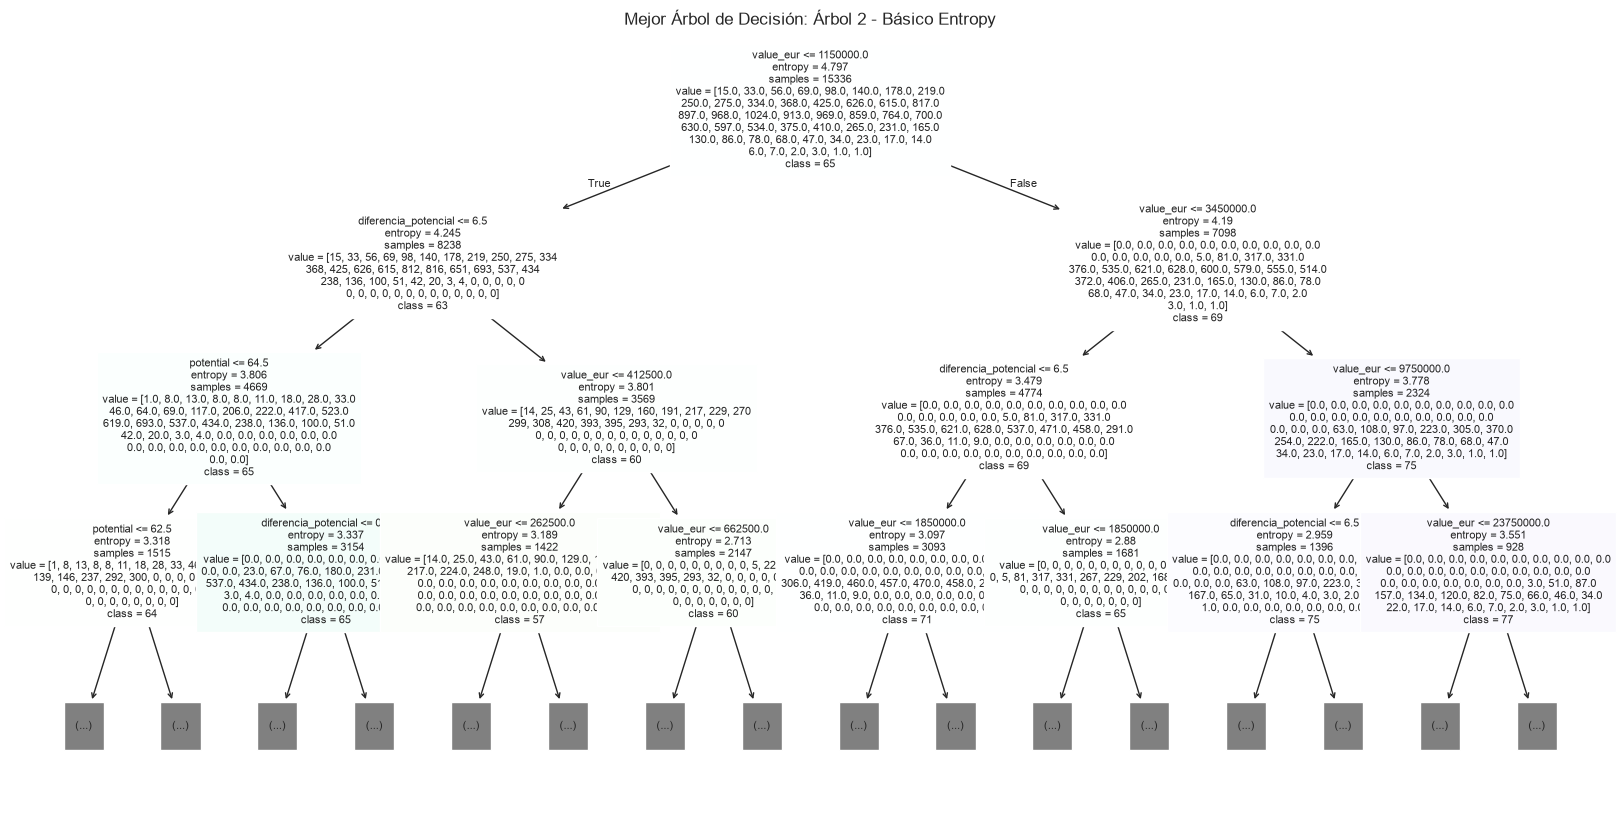

In [26]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import matplotlib.pyplot as plt

tree_configs = {
    'Árbol 1 - Básico Gini': {
        'max_depth': None,
        'min_samples_leaf': 1,
        'criterion': 'gini'
    },
    'Árbol 2 - Básico Entropy': {
        'max_depth': None,
        'min_samples_leaf': 1,
        'criterion': 'entropy'
    },
    'Árbol 3 - Profundidad 5': {
        'max_depth': 5,
        'min_samples_leaf': 1,
        'criterion': 'gini'
    },
    'Árbol 4 - Profundidad 10': {
        'max_depth': 10,
        'min_samples_leaf': 5,
        'criterion': 'gini'
    },
    'Árbol 5 - Profundidad 15 Entropy': {
        'max_depth': 15,
        'min_samples_leaf': 3,
        'criterion': 'entropy'
    },
    'Árbol 6 - Árbol regularizado': {
        'max_depth': 20,
        'min_samples_leaf': 10,
        'criterion': 'entropy'
    }
}

tree_results = []

for nombre, parametros in tree_configs.items():
    modelo = DecisionTreeClassifier(
        **parametros,
        random_state=42
    )

    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)

    tree_results.append({
        'modelo': nombre,
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(
            y_test, y_pred, average='weighted', zero_division=0
        ),
        'recall': recall_score(
            y_test, y_pred, average='weighted', zero_division=0
        ),
        'f1': f1_score(
            y_test, y_pred, average='weighted', zero_division=0
        )
    })

# Mostrar resultados
tree_results_df = pd.DataFrame(tree_results)
display(tree_results_df.round(4))

# Seleccionar el mejor árbol según F1
mejor_nombre = tree_results_df.loc[
    tree_results_df['f1'].idxmax(), 'modelo'
]

mejor_parametros = tree_configs[mejor_nombre]

mejor_arbol = DecisionTreeClassifier(
    **mejor_parametros,
    random_state=42
)

mejor_arbol.fit(X_train, y_train)

# Representar el árbol
plt.figure(figsize=(20, 10))
plot_tree(
    mejor_arbol,
    feature_names=X_train.columns,
    class_names=[str(clase) for clase in mejor_arbol.classes_],
    filled=True,
    max_depth=3,
    fontsize=8
)

plt.title(f'Mejor Árbol de Decisión: {mejor_nombre}')
plt.show()

La mejor configuración obtenida ha sido el Árbol 2 básico con entornopy. Este Árbol es capaz de clasificar correctamente el 96.3% de los jugadores del conjunto de prueba. El peor de los árboles limitado a una profundidad de 5 con un f1 de 0.3739. Al ser demasiado simple no consiguió aprender sufientemente bienlas diferencias. 

Los árboles con mayor profundidad y el criterio `entropy` obtienen mejores resultados. 

2.2.2 Naive Bayes

Es un algoritmo de clasificación basado en el teorema de Bayes. Calcula la probabilidad de que un jugador pertenezca a una categoría. 
Utilizamos `GaussianNB`porque trabaja con variables numéricas continias previamente estandarizadas. Se prueban seis valores `var_smoothin`para mejorar la estabilidad del modelo y se selecciona la configuración con mayor puntuación 


In [30]:
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB

# Escalar los mismos datos que corresponden a y_train
scaler_nb = StandardScaler()

X_train_nb = pd.DataFrame(
    scaler_nb.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_nb = pd.DataFrame(
    scaler_nb.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

nb_results = []

for nombre, parametros in nb_configs.items():
    modelo = GaussianNB(**parametros)

    modelo.fit(X_train_nb, y_train)
    y_pred = modelo.predict(X_test_nb)

    nb_results.append({
        'modelo': nombre,
        'var_smoothing': parametros['var_smoothing'],
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        ),
        'recall': recall_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        ),
        'f1': f1_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        )
    })
# Convertir los resultados en una tabla
nb_results_df = pd.DataFrame(nb_results)

# Ordenar por la métrica F1
nb_results_df = nb_results_df.sort_values(
    by='f1',
    ascending=False
)

# Mostrar resultados
display(nb_results_df.round(4))

# Mostrar la mejor configuración
print("Mejor configuración de Naive Bayes:")
display(nb_results_df.iloc[[0]])

print("La celda se ha ejecutado")
print(len(nb_results))

,modelo,var_smoothing,accuracy,precision,recall,f1
1,Naive Bayes 2,0.0,0.0023,0.0136,0.0023,0.0013
0,Naive Bayes 1,0.0,0.0023,0.0136,0.0023,0.0013
5,Naive Bayes 6,0.0,0.0041,0.0005,0.0041,0.0009
4,Naive Bayes 5,0.0,0.0035,0.0005,0.0035,0.0008
3,Naive Bayes 4,0.0,0.0029,0.0004,0.0029,0.0006
2,Naive Bayes 3,0.0,0.0018,0.0001,0.0018,0.0002


Mejor configuración de Naive Bayes:


,modelo,var_smoothing,accuracy,precision,recall,f1
1,Naive Bayes 2,1.000000e-10,0.002346,0.013606,0.002346,0.001332


La celda se ha ejecutado
6


#### 2.2.3 SVM



Es un algoritmo de clasificación que busca la frontera óptima para separar las categorías. Intenta maximizar la distancia entre la frontera y los ejemplos más cercanos de cada clase.

En nuestro caso, se ha aplicado sobre las variables previamente estandarizadas.  Se han probado seis configuraciones modificando: 

* `C`: controla el equilibrio entre errores y complejidad del modelo.
* `kernel`: se han utilizado `linear` y `rbf`.
* `gamma`: controla la influencia de cada observación en el kernel RBF.
Cada configuración se entrena con el 90 % de los datos y se evalúa con el 10 % restante. Finalmente, se comparan accuracy, precision, recall y F1, seleccionando como mejor modelo el que obtiene el valor más alto de F1


In [31]:
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

svm_configs = {
    'SVM 1 - Lineal C=0.1': {
        'C': 0.1,
        'kernel': 'linear'
    },
    'SVM 2 - Lineal C=1': {
        'C': 1,
        'kernel': 'linear'
    },
    'SVM 3 - Lineal C=10': {
        'C': 10,
        'kernel': 'linear'
    },
    'SVM 4 - RBF C=1': {
        'C': 1,
        'kernel': 'rbf',
        'gamma': 'scale'
    },
    'SVM 5 - RBF C=10': {
        'C': 10,
        'kernel': 'rbf',
        'gamma': 'scale'
    },
    'SVM 6 - RBF C=10 gamma=0.1': {
        'C': 10,
        'kernel': 'rbf',
        'gamma': 0.1
    }
}

svm_results = []

for nombre, parametros in svm_configs.items():
    modelo = SVC(**parametros)

    modelo.fit(X_train_nb, y_train)
    y_pred = modelo.predict(X_test_nb)

    svm_results.append({
        'modelo': nombre,
        'C': parametros['C'],
        'kernel': parametros['kernel'],
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        ),
        'recall': recall_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        ),
        'f1': f1_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        )
    })

# Mostrar resultados ordenados por F1
svm_results_df = pd.DataFrame(svm_results)

display(
    svm_results_df
    .sort_values('f1', ascending=False)
    .round(4)
)

# Mostrar la mejor configuración
print("Mejor configuración de SVM:")
display(
    svm_results_df
    .sort_values('f1', ascending=False)
    .iloc[[0]]
)

,modelo,C,kernel,accuracy,precision,recall,f1
2,SVM 3 - Lineal C=10,10.0,linear,0.9953,0.9956,0.9953,0.9953
1,SVM 2 - Lineal C=1,1.0,linear,0.9836,0.9847,0.9836,0.9830
0,SVM 1 - Lineal C=0.1,0.1,linear,0.8006,0.7867,0.8006,0.7888
4,SVM 5 - RBF C=10,10.0,rbf,0.7754,0.7786,0.7754,0.7747
5,SVM 6 - RBF C=10 gamma=0.1,10.0,rbf,0.6733,0.6761,0.6733,0.6715
3,SVM 4 - RBF C=1,1.0,rbf,0.3032,0.2915,0.3032,0.2842


Mejor configuración de SVM:


,modelo,C,kernel,accuracy,precision,recall,f1
2,SVM 3 - Lineal C=10,10.0,linear,0.995308,0.995646,0.995308,0.995349


#### 2.2.4 Random Forest


Es un modelo que combina múltiples árboles de decisión. Cada árbol analiza una parte de datos y de las variables, y la predicción final que se obtiene mediante la votación de todos los árboles.

En nuestro caso, utilizamos rste modelo para clasificar jugadores en las categorías. Probamos seis configuraciones:

* `n_estimators`: número de árboles.
* `max_depth`: profundidad máxima.
* `min_samples_leaf`: mínimo de muestras en cada hoja.
* `criterion`: criterio `gini` o `entropy`

Random Forest suele ofrecer resultados estables y reduce el riesgo de sobreajuste. 


In [34]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

forest_configs = {
    'Random Forest 1 - Básico': {
        'n_estimators': 100,
        'max_depth': None,
        'min_samples_leaf': 1,
        'criterion': 'gini'
    },
    'Random Forest 2 - Entropy': {
        'n_estimators': 100,
        'max_depth': None,
        'min_samples_leaf': 1,
        'criterion': 'entropy'
    },
    'Random Forest 3 - Profundidad 10': {
        'n_estimators': 200,
        'max_depth': 10,
        'min_samples_leaf': 1,
        'criterion': 'gini'
    },
    'Random Forest 4 - Profundidad 15': {
        'n_estimators': 200,
        'max_depth': 15,
        'min_samples_leaf': 2,
        'criterion': 'entropy'
    },
    'Random Forest 5 - Regularizado': {
        'n_estimators': 300,
        'max_depth': 20,
        'min_samples_leaf': 5,
        'criterion': 'gini'
    },
    'Random Forest 6 - Robusto': {
        'n_estimators': 300,
        'max_depth': 25,
        'min_samples_leaf': 2,
        'criterion': 'entropy'
    }
}

forest_results = []

for nombre, parametros in forest_configs.items():
    modelo = RandomForestClassifier(
        **parametros,
        random_state=42,
        n_jobs=-1
    )

    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)

    forest_results.append({
        'modelo': nombre,
        **parametros,
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        ),
        'recall': recall_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        ),
        'f1': f1_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        )
    })

# Mostrar resultados
forest_results_df = pd.DataFrame(forest_results)

display(
    forest_results_df
    .sort_values('f1', ascending=False)
    .round(4)
)

# Mostrar la mejor configuración
print("Mejor configuración de Random Forest:")
display(
    forest_results_df
    .sort_values('f1', ascending=False)
    .iloc[[0]]
)


,modelo,n_estimators,max_depth,min_samples_leaf,criterion,accuracy,precision,recall,f1
1,Random Forest 2 - Entropy,100,NaN,1,entropy,0.8258,0.8281,0.8258,0.8229
5,Random Forest 6 - Robusto,300,25.0,2,entropy,0.8235,0.8257,0.8235,0.8189
0,Random Forest 1 - Básico,100,NaN,1,gini,0.8123,0.8136,0.8123,0.8100
3,Random Forest 4 - Profundidad 15,200,15.0,2,entropy,0.8065,0.8092,0.8065,0.8015
4,Random Forest 5 - Regularizado,300,20.0,5,gini,0.7812,0.7838,0.7812,0.7740
2,Random Forest 3 - Profundidad 10,200,10.0,1,gini,0.7103,0.7281,0.7103,0.6983


Mejor configuración de Random Forest:


,modelo,n_estimators,max_depth,min_samples_leaf,criterion,accuracy,precision,recall,f1
1,Random Forest 2 - Entropy,100,NaN,1,entropy,0.825806,0.828062,0.825806,0.822852
